# Projet Big Data - Détection d'intrusion IoT (Edge-IIoTset)

Classification du type d'attaque réseau sur le dataset Edge-IIoTset.
Cible : `Attack_type` (15 classes : trafic normal + 14 attaques).

### Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, ConfusionMatrixDisplay


### Chargement des données

In [2]:
df = pd.read_csv("ML-EdgeIIoT-dataset.csv", low_memory=False)
print(df.shape)
df.head()


(157800, 63)


,frame.time,ip.src_host,ip.dst_host,arp.dst.proto_ipv4,arp.opcode,arp.hw.size,arp.src.proto_ipv4,icmp.checksum,icmp.seq_le,icmp.transmit_timestamp,...,mqtt.proto_len,mqtt.protoname,mqtt.topic,mqtt.topic_len,mqtt.ver,mbtcp.len,mbtcp.trans_id,mbtcp.unit_id,Attack_label,Attack_type
0,6.0,192.168.0.152,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,MITM
1,6.0,192.168.0.101,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,MITM
2,6.0,192.168.0.152,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,MITM
3,6.0,192.168.0.101,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,MITM
4,6.0,192.168.0.152,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,MITM


### Exploration

In [3]:
# types et infos générales
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 157800 entries, 0 to 157799
Data columns (total 63 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   frame.time                 157800 non-null  str    
 1   ip.src_host                157800 non-null  str    
 2   ip.dst_host                157800 non-null  str    
 3   arp.dst.proto_ipv4         157800 non-null  str    
 4   arp.opcode                 157800 non-null  float64
 5   arp.hw.size                157800 non-null  float64
 6   arp.src.proto_ipv4         157800 non-null  str    
 7   icmp.checksum              157800 non-null  float64
 8   icmp.seq_le                157800 non-null  float64
 9   icmp.transmit_timestamp    157800 non-null  float64
 10  icmp.unused                157800 non-null  float64
 11  http.file_data             157800 non-null  str    
 12  http.content_length        157800 non-null  float64
 13  http.request.uri.query     157800 non-nu

In [4]:
# valeurs manquantes et doublons
print("valeurs manquantes :", df.isna().sum().sum())
print("doublons :", df.duplicated().sum())


valeurs manquantes : 0
doublons : 814


In [5]:
# combien de lignes par type d'attaque
df["Attack_type"].value_counts()


Attack_type
Normal                   24301
DDoS_UDP                 14498
DDoS_ICMP                14090
Ransomware               10925
DDoS_HTTP                10561
SQL_injection            10311
Uploading                10269
DDoS_TCP                 10247
Backdoor                 10195
Vulnerability_scanner    10076
Port_Scanning            10071
XSS                      10052
Password                  9989
MITM                      1214
Fingerprinting            1001
Name: count, dtype: int64

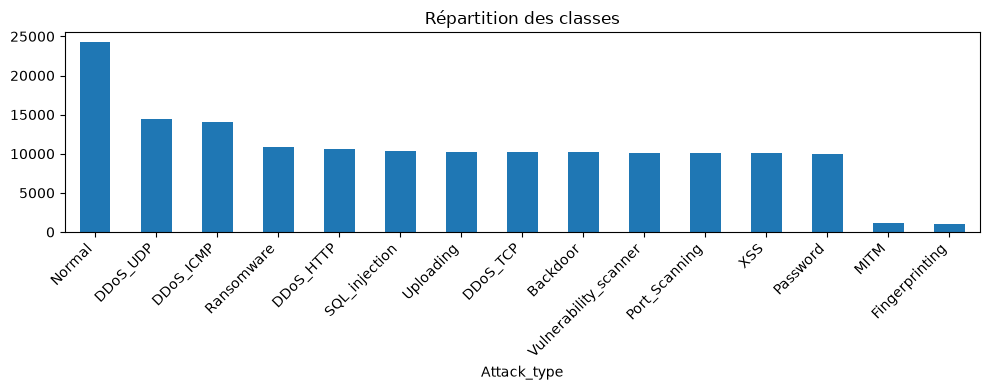

In [6]:
# on visualise la répartition
plt.figure(figsize=(10,4))
df["Attack_type"].value_counts().plot(kind="bar")
plt.title("Répartition des classes")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


### Nettoyage

On enlève les colonnes qui servent d'identifiants ou qui peuvent fausser le modèle
(adresses IP/MAC, payloads, URI...), puis on retire les lignes vides et les doublons.

In [7]:
cols_a_supprimer = ["frame.time","ip.src_host","ip.dst_host","arp.src.proto_ipv4",
    "arp.dst.proto_ipv4","http.file_data","http.request.full_uri",
    "icmp.transmit_timestamp","http.request.uri.query","tcp.options",
    "tcp.payload","tcp.srcport","tcp.dstport","udp.port","mqtt.msg"]

df = df.drop(columns=cols_a_supprimer, errors="ignore")
df = df.dropna()
df = df.drop_duplicates()
df = df.sample(frac=1, random_state=42).reset_index(drop=True)
print("après nettoyage :", df.shape)


après nettoyage : (152196, 48)


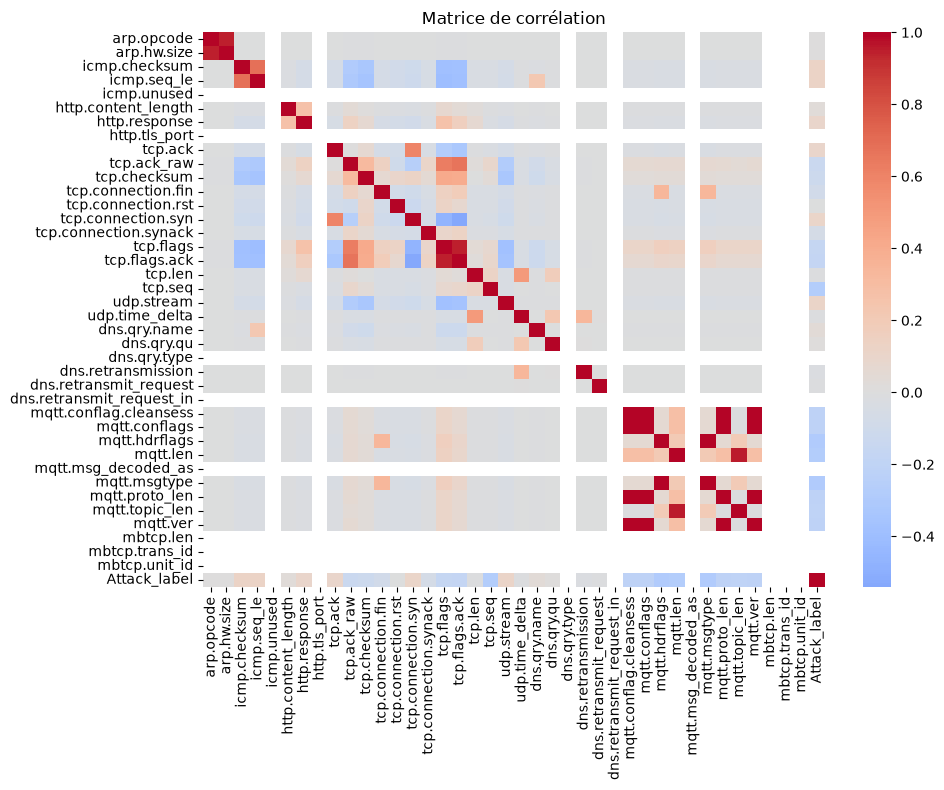

In [8]:
# corrélation entre les variables numériques
plt.figure(figsize=(10,8))
sns.heatmap(df.select_dtypes(include=[np.number]).corr(), cmap="coolwarm", center=0)
plt.title("Matrice de corrélation")
plt.tight_layout()
plt.show()


### Préparation X / y

In [11]:
# la cible, convertie en nombres
le = LabelEncoder()
y = le.fit_transform(df["Attack_type"].astype(str))
classes = le.classes_

# les features : on enlève les deux colonnes cibles pour éviter la triche
X = df.drop(columns=["Attack_label", "Attack_type"])

# on transforme les colonnes texte en colonnes numériques
cat = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]
print("colonnes texte encodées :", cat)
X = pd.get_dummies(X, columns=cat)
print(X.shape)


colonnes texte encodées : ['http.request.method', 'http.referer', 'http.request.version', 'dns.qry.name.len', 'mqtt.conack.flags', 'mqtt.protoname', 'mqtt.topic']
(152196, 74)


### Séparation train / test (60 / 40)

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.4, random_state=42, stratify=y)

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

print("train :", X_train.shape)
print("test  :", X_test.shape)


train : (91317, 74)
test  : (60879, 74)


### Entraînement des modèles

In [18]:
modeles = {
    "Regression Logistique": LogisticRegression(max_iter=1000),
    "Arbre de decision": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
}

for nom, m in modeles.items():
    m.fit(X_train, y_train)
    print(nom, "ok")


Regression Logistique ok
Arbre de decision ok
Random Forest ok


### Évaluation

In [14]:
resultats = []
for nom, m in modeles.items():
    pred = m.predict(X_test)
    resultats.append({
        "Modele": nom,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_test, pred, average="weighted", zero_division=0),
        "F1": f1_score(y_test, pred, average="weighted", zero_division=0),
    })

pd.DataFrame(resultats).set_index("Modele").round(4)


,Accuracy,Precision,Recall,F1
Modele,,,,
Regression Logistique,0.7683,0.7931,0.7683,0.7662
Arbre de decision,0.9257,0.9257,0.9257,0.9257
Random Forest,0.9287,0.9291,0.9287,0.9287


In [15]:
# rapport détaillé du meilleur modèle
best = RandomForestClassifier(n_estimators=100, random_state=42)
best.fit(X_train, y_train)
pred = best.predict(X_test)

print(classification_report(y_test, pred, target_names=[str(c) for c in classes], zero_division=0))


                       precision    recall  f1-score   support

             Backdoor       0.97      0.95      0.96      3946
            DDoS_HTTP       0.83      0.89      0.86      4198
            DDoS_ICMP       1.00      1.00      1.00      5238
             DDoS_TCP       1.00      1.00      1.00      4099
             DDoS_UDP       1.00      1.00      1.00      5799
       Fingerprinting       0.82      0.72      0.77       341
                 MITM       1.00      1.00      1.00       143
               Normal       1.00      1.00      1.00      9641
             Password       0.77      0.77      0.77      3989
        Port_Scanning       0.94      1.00      0.97      3568
           Ransomware       0.96      0.93      0.95      3876
        SQL_injection       0.81      0.82      0.81      4113
            Uploading       0.81      0.80      0.80      4086
Vulnerability_scanner       0.98      0.95      0.97      4025
                  XSS       0.87      0.83      0.85  

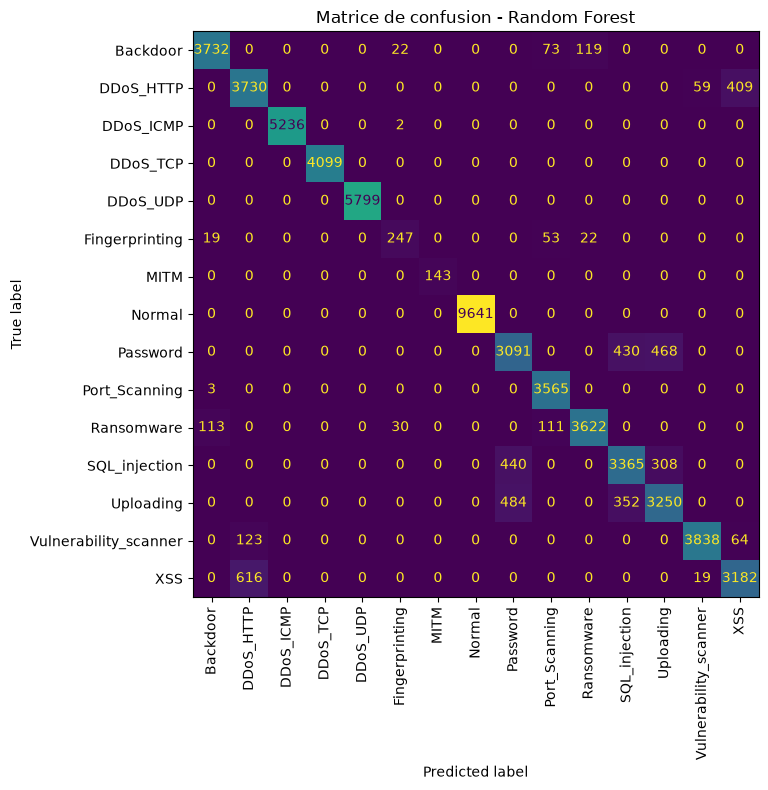

In [16]:
# matrice de confusion
fig, ax = plt.subplots(figsize=(9,8))
ConfusionMatrixDisplay.from_predictions(y_test, pred,
    display_labels=[str(c) for c in classes], xticks_rotation=90, ax=ax, colorbar=False)
plt.title("Matrice de confusion - Random Forest")
plt.tight_layout()
plt.show()
